# NB1 · Dữ liệu: nạp → tiền xử lý → EDA → chuẩn hóa → sẵn sàng huấn luyện & đánh giá
**Chatbot CSKH Kimochi Sushi** — Hybrid-RAG + Fine-tuning Qwen2.5-3B / LLaMA-3.2-3B (LoRA / QLoRA)

Chạy trên **CPU** (~2 phút), tái lập hoàn toàn (seed 42, cùng md5 mỗi lần chạy). Đầu ra dùng cho `NB2_finetune_rag_mvp.ipynb`.

| § | Nội dung | Đầu ra |
|---|---|---|
| 1 | Nạp & khảo sát dữ liệu gốc | — |
| 2 | Kho tri thức: SQLite + tài liệu RAG (chunk ≤ 600 ký tự) | `data/kimochi.db`, `data/kb/` |
| 3 | Chất lượng dữ liệu: thiếu giá, giá mâu thuẫn (VAT) | `results/kb_quality.json` |
| 4 | Gán nhãn intent & tạo đặc trưng | — |
| 5 | Chia train / val / test theo nhóm + kiểm rò rỉ | `data/splits/` (tập test chính thức) |
| 6 | EDA & phát hiện kinh doanh | `images/eda_*.png` |
| 7 | Chuẩn hóa → bộ dữ liệu huấn luyện v2 (công cụ SQL, RAFT, hội thoại nhiều lượt, từ chối) | `data/splits_v2/` |
| 8 | Kiểm tra sẵn sàng huấn luyện & đánh giá | — |
| 9 | Manifest md5 (NB2 kiểm tra lại) | `data/MANIFEST.json` |

In [1]:
import sys, os, json, pathlib
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
# tìm thư mục gốc repo (chứa code/src/kimochi) — chạy được cả local lẫn Kaggle / Colab
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'code/src/kimochi').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / 'code/src'))
pd.set_option('display.max_colwidth', 90); pd.set_option('display.width', 160)
print('ROOT =', ROOT)

ROOT = /home/user/project-samsung-ai-campus-2026


## 1. Nạp & khảo sát dữ liệu gốc
`data/KIMOCHI_DATA_TRAINING_CHATBOT.json` — bộ hỏi–đáp kế thừa phiên bản trước, dựa trên thông tin thật của nhà hàng.

In [2]:
raw = pd.read_json('data/KIMOCHI_DATA_TRAINING_CHATBOT.json')
print(raw.shape); display(raw.head(5))
print('Giá trị thiếu:', raw.isna().sum().to_dict())
print('Domain khác nhau:', raw.Domain.nunique(), '| câu hỏi khác nhau:', raw.user_query.nunique(),
      '| câu trả lời khác nhau:', raw.responses.nunique())
print('Cặp (hỏi, đáp) trùng nguyên văn:', raw.duplicated(['user_query', 'responses']).sum())

(6355, 3)


,Domain,user_query,responses
0,Hương vị: Salad Rong Biển,Salad Rong Biển có vị gì vậy ạ?,"Dạ Salad Rong Biển có vị chua ngọt thanh mát, không hề cay đâu ạ. 😋"
1,Hương vị: Salad Rong Biển,Vị salad này sao ta?,"Dạ Salad Rong Biển có vị chua ngọt thanh mát, không hề cay đâu ạ. 😋"
2,Hương vị: Salad Rong Biển,salad rong bien vi gi the,"Dạ Salad Rong Biển có vị chua ngọt thanh mát, không hề cay đâu ạ. 😋"
3,Thành phần: Salad Rong Biển,Salad Rong Biển có những thành phần chính nào?,"Dạ món này có rong biển chuka, rong nho, bắp cải, cà chua bi và sốt mè đó ạ. 🥬"
4,Thành phần: Salad Rong Biển,Rong nho có hong?,"Dạ món này có rong biển chuka, rong nho, bắp cải, cà chua bi và sốt mè đó ạ. 🥬"


Giá trị thiếu: {'Domain': 0, 'user_query': 0, 'responses': 0}
Domain khác nhau: 1902 | câu hỏi khác nhau: 6069 | câu trả lời khác nhau: 2068
Cặp (hỏi, đáp) trùng nguyên văn: 53


**Nhận xét.** Không có giá trị thiếu, nhưng ~6.000 câu hỏi chỉ dùng ~2.000 câu trả lời → mỗi đáp án có ~3 cách hỏi (diễn đạt lại).
Đây là nguy cơ **rò rỉ dữ liệu** nếu chia train/test ngẫu nhiên theo dòng → §5 chia theo nhóm câu trả lời.

## 2. Kho tri thức: cơ sở dữ liệu SQL + tài liệu RAG
Trích **tên món chính tắc**, giá, danh mục, nhóm dị ứng (suy luận từ khóa, gắn cờ *chưa xác nhận*) → SQLite 6 bảng;
mỗi món / chủ đề → một tài liệu, cắt thành **chunk ≤ 600 ký tự** (đơn vị truy xuất dùng chung cho huấn luyện RAFT và lúc chạy).
Bàn / đặt bàn là dữ liệu **mô phỏng** (`simulated = 1`).

In [3]:
from kimochi import build_kb
kbq = build_kb.main()
menu = pd.read_csv('data/kb/menu.csv')
print({k: kbq[k] for k in ['raw_rows', 'rows_mapped_to_item', 'menu_items', 'items_with_price', 'chunks', 'docs_menu', 'docs_policy']})
display(menu.drop(columns='description').head(8))

{'raw_rows': 6355, 'rows_mapped_to_item': 4108, 'menu_items': 106, 'items_with_price': 74, 'chunks': 1019, 'docs_menu': 106, 'docs_policy': 545}


,item_id,name,category,price_vnd,allergens,is_vegetarian,spicy_level,allergen_verified,n_samples
0,M001,Combo Kaki Salmon Chuka,Combo,215000.0,cá;giáp xác;gluten;nhuyễn thể;sữa,0,0,0,45
1,M002,Combo Kani Salmon,Combo,197000.0,cá;giáp xác;gluten;sữa;trứng,0,1,0,45
2,M003,Combo Maki 215K,Combo,215000.0,cá;giáp xác;gluten;sữa,0,0,0,45
3,M004,Combo Oishi 1,Combo,NaN,cá;trứng,0,0,0,54
4,M005,Combo Oishi 2,Combo,NaN,cá;trứng,0,0,0,54
5,M006,Combo Oishi 3,Combo,NaN,cá,0,0,0,54
6,M007,Combo Oishi 4,Combo,NaN,cá;nhuyễn thể;trứng,0,0,0,54
7,M008,Combo Oishi 5,Combo,NaN,cá;nhuyễn thể;trứng,0,0,0,54


In [4]:
import sqlite3
con = sqlite3.connect('data/kimochi.db')
dd = pd.DataFrame([{'bảng': t, 'số dòng': con.execute(f'select count(*) from {t}').fetchone()[0],
                    'cột': ', '.join(r[1] for r in con.execute(f'pragma table_info({t})'))}
                   for t in ['categories', 'menu_items', 'branches', 'tables', 'reservations', 'promotions']])
display(dd)   # từ điển dữ liệu của cơ sở dữ liệu
chunks = pd.read_json('data/kb/chunks.jsonl', lines=True)
print('Chunk:', len(chunks), '| độ dài ký tự:', chunks.text.str.len().describe().round(0).to_dict())

,bảng,số dòng,cột
0,categories,9,"category_id, name"
1,menu_items,106,"item_id, name, category_id, price_vnd, allergens, allergen_verified, is_vegetarian, sp..."
2,branches,2,"branch_id, name, district, address, hotline, open_time, close_time, seating"
3,tables,24,"table_id, branch_id, seats, kind, simulated"
4,reservations,0,"reservation_id, branch_id, table_id, customer_name, phone, party_size, start_at, statu..."
5,promotions,1,"promo_id, title, condition, benefit, valid_from, valid_to, simulated"


Chunk: 1019 | độ dài ký tự: {'count': 1019.0, 'mean': 364.0, 'std': 162.0, 'min': 41.0, '25%': 254.0, '50%': 329.0, '75%': 502.0, 'max': 1543.0}


## 3. Chất lượng dữ liệu — thiếu giá và giá mâu thuẫn
Đối chiếu giá trong câu trả lời hỏi giá với giá nhắc kèm tên món ở **mọi** câu trả lời khác.

In [5]:
miss = menu[menu.price_vnd.isna()].groupby('category').size().rename('món thiếu giá')
display(miss.to_frame())
xc = kbq['price_mismatch_detail']
vat = lambda db, p: abs(int(p) - round(db * 1.1, -2)) <= 200
tab = pd.DataFrame([{'món': k, 'giá DB': v['db'], 'giá khác': ', '.join(f'{int(p):,} (×{c})' for p, c in v['other_mentions'].items()),
                     'giải thích bằng VAT 10%': all(vat(v['db'], p) for p in v['other_mentions'])} for k, v in xc.items()])
print(f"{len(tab)}/{kbq['items_with_price']} món có giá mâu thuẫn; {tab['giải thích bằng VAT 10%'].sum()} món chênh đúng VAT 10%")
display(tab.head(12))

,món thiếu giá
category,
Combo,10
Maki / Cơm cuộn,2
Món nóng / Khai vị,6
Salad,5
Sashimi,9


26/74 món có giá mâu thuẫn; 16 món chênh đúng VAT 10%


,món,giá DB,giá khác,giải thích bằng VAT 10%
0,Combo Kaki Salmon Chuka,215000,"236,500 (×2)",True
1,Combo Tuna Fuji,233000,"256,300 (×4)",True
2,Cơm Bò Xào,109000,"119,900 (×27)",True
3,Cơm Gà Chiên Giòn,109000,"119,900 (×22)",True
4,Cơm Gà Chiên Miso Cay,109000,"119,900 (×1)",True
5,Cơm Lươn,209000,"229,900 (×15)",True
6,Cơm Trộn Sansou Don Buri,169000,"108,900 (×9), 185,900 (×3)",False
7,Cơm trắng,15000,"16,500 (×3)",True
8,Mì Ramen Xào Bò,108000,"108,900 (×3)",False
9,Mì Ramen Xào Hải Sản,89000,"97,900 (×6)",True


**Nhận xét.** Dữ liệu trộn giá trước và sau VAT, cộng thêm một số mâu thuẫn không giải thích được. Nếu để mô hình *học thuộc*
giá từ hội thoại, nó sẽ học cả các con số mâu thuẫn → **nguyên tắc thiết kế: giá chỉ đọc qua công cụ SQL** (§7).
Giá thiếu được giữ NULL (không điền ước lượng) — điền sai giá gây thiệt hại trực tiếp.

## 4. Gán nhãn intent & tạo đặc trưng
Intent theo luật từ khóa có thứ tự ưu tiên (intent giá chỉ xét câu hỏi, vì `Domain` kiểu "Giá & Hương vị: X" chứa cả câu hỏi
không về giá). Đặc trưng tạo mới: `group_id` (băm câu trả lời), `noisy_input` (không dấu / teen code), `needs_tool`, `difficulty`.

In [6]:
from kimochi import prepare_sft
fr = prepare_sft.build_frame()
display(fr[['user_query', 'intent', 'group_id', 'noisy_input', 'unaccented', 'needs_tool', 'difficulty']].sample(8, random_state=1))
display(fr.intent.value_counts().rename('số mẫu').to_frame().assign(tỷ_lệ=lambda d: (d['số mẫu'] / len(fr)).round(3)))

,user_query,intent,group_id,noisy_input,unaccented,needs_tool,difficulty
6107,Combo Oishi 5 cs cay k?,menu_info,g-711506b42b,True,True,rag,easy
1548,Bạch Tuộc Sống Trộn Wasabi có nước chấm kèm không ạ?,allergy_diet,g-2ca17f9d49,False,False,rag,hard
2983,tom tempura tanh hem z shop?,allergy_diet,g-d2c0213675,True,True,rag,hard
3232,mai cua de an hem v shop?,menu_info,g-0e0da8b913,True,True,rag,easy
3584,Bữa trưa đầy đủ no bụng cho dân văn phòng.,menu_info,g-3ef5b5d250,False,False,rag,medium
2174,canh ga sot teri co hop tre em khong,allergy_diet,g-4e39d2a17c,True,True,rag,hard
2385,Làm sao để thưởng thức Cá Ngừ Sốt Ponzu đúng điệu nhất vậy shop?,menu_info,g-3b3dfaa479,True,False,rag,medium
3551,tau hu bo xao co hinh khong,menu_info,g-da4925cbae,True,True,rag,easy


,số mẫu,tỷ_lệ
intent,,
menu_info,3798,0.598
recommendation,877,0.138
allergy_diet,792,0.125
price_query,488,0.077
policy_promo,224,0.035
store_info,116,0.018
reservation_create,36,0.006
complaint,24,0.004


## 5. Chia train / val / test theo nhóm + kiểm tra rò rỉ
`StratifiedGroupKFold` (10 fold, seed 42): 1 fold test, 1 fold val, 8 fold train — chia **theo `group_id`**, phân tầng theo intent.
Sau đó so cosine (TF-IDF n-gram ký tự, văn bản bỏ dấu) giữa mỗi câu val/test và câu train gần nhất; loại cặp > 0,92.
**Tập test này (cùng bộ test viết tay `test_gold` / `test_adv`) là tập đánh giá chính thức cho mọi mô hình ở NB2.**

In [7]:
st = prepare_sft.main()
print('Kích thước:', st['split_sizes'])
print('Số nhóm giao nhau train ↔ test:', st['group_overlap_train_test'])
print('Rò rỉ:', json.dumps(st['leakage'], indent=1))
display(pd.DataFrame(st['intent_by_split']).fillna(0).astype(int))

Kích thước: {'train': 5085, 'test_synth': 577, 'val': 557, 'dropped_leak': 136}
Số nhóm giao nhau train ↔ test: 0
Rò rỉ: {
 "val": {
  "n": 633,
  "cos_mean": 0.7811684215505108,
  "cos_p95": 1.0,
  "n_over_threshold": 76
 },
 "test_synth": {
  "n": 637,
  "cos_mean": 0.7742228899370638,
  "cos_p95": 0.9477894045602588,
  "n_over_threshold": 60
 },
 "dropped_leak": 136
}


,dropped_leak,test_synth,train,val
allergy_diet,22,69,634,67
complaint,0,3,18,3
menu_info,81,342,3039,336
policy_promo,6,23,179,16
price_query,7,46,390,45
recommendation,19,79,704,75
reservation_create,0,3,29,4
store_info,1,12,92,11


## 6. EDA & phát hiện kinh doanh
Mỗi hình đi kèm nhận xét; số liệu đọc từ `results/eda_stats.json`.

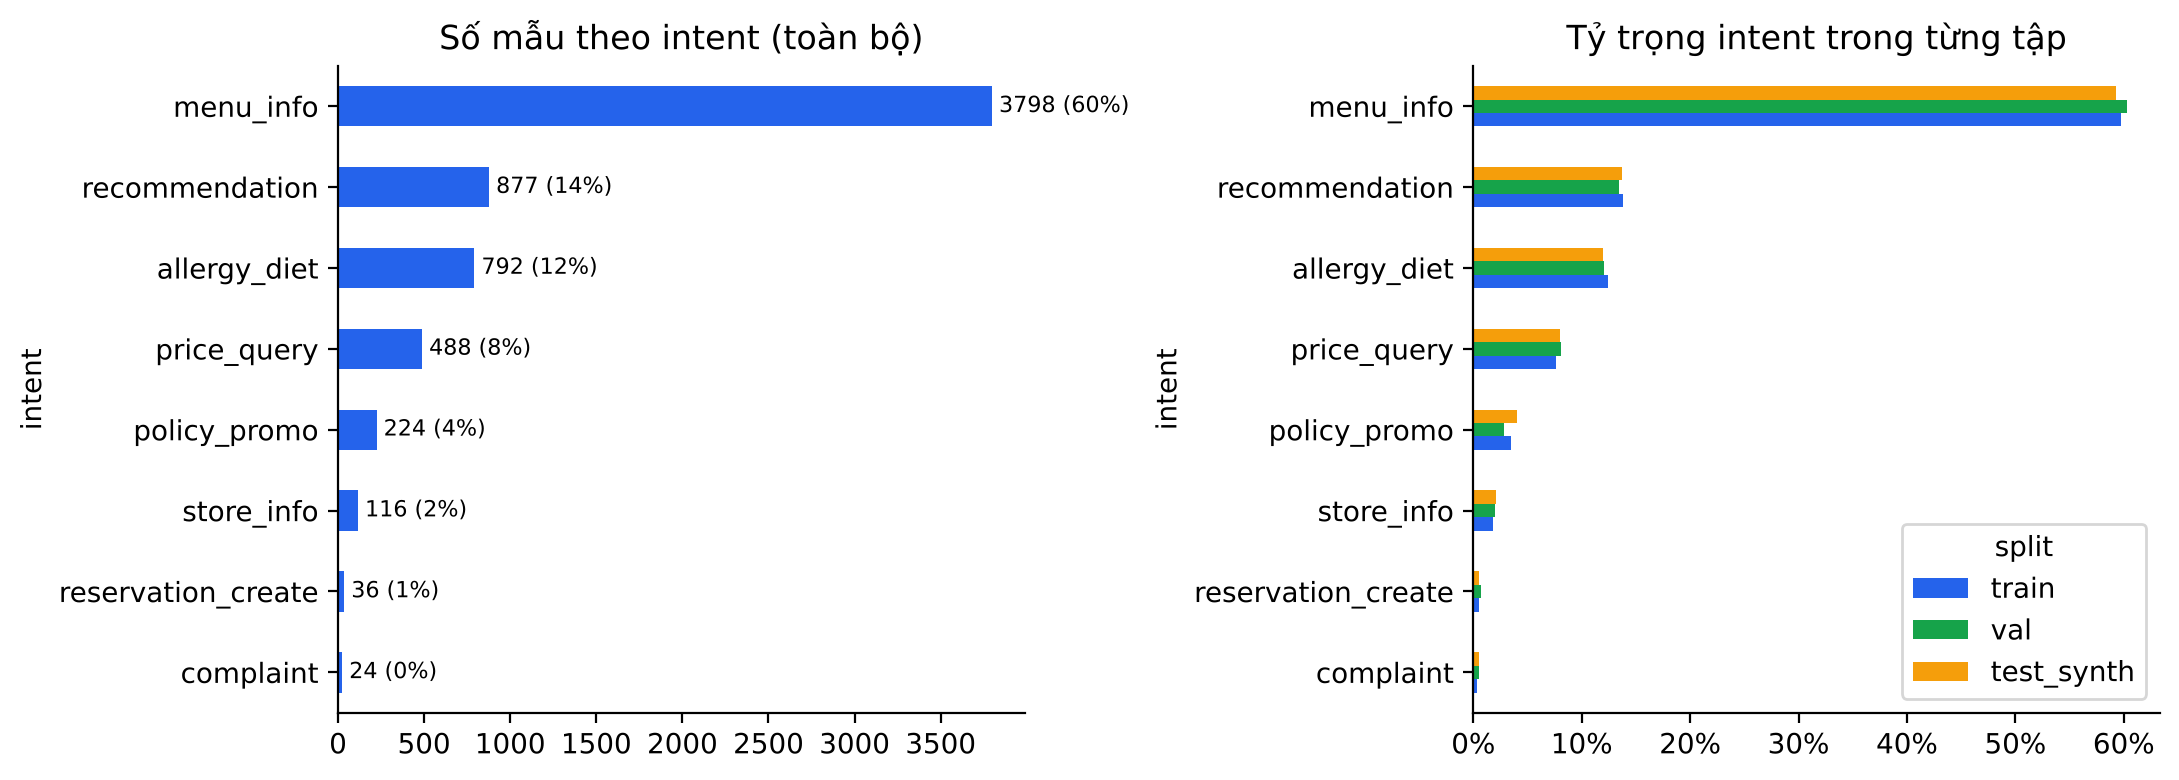

**Intent lệch mạnh:** menu_info 60%, recommendation 14%, allergy 12.5%, price 8%; đặt bàn chỉ 0.6%. Dữ liệu cũ thiên về giới thiệu thực đơn, thiếu tác vụ giao dịch → bổ sung ở §7. Tỷ trọng intent giữa các tập lệch tối đa 0.5 điểm % (phân tầng tốt).

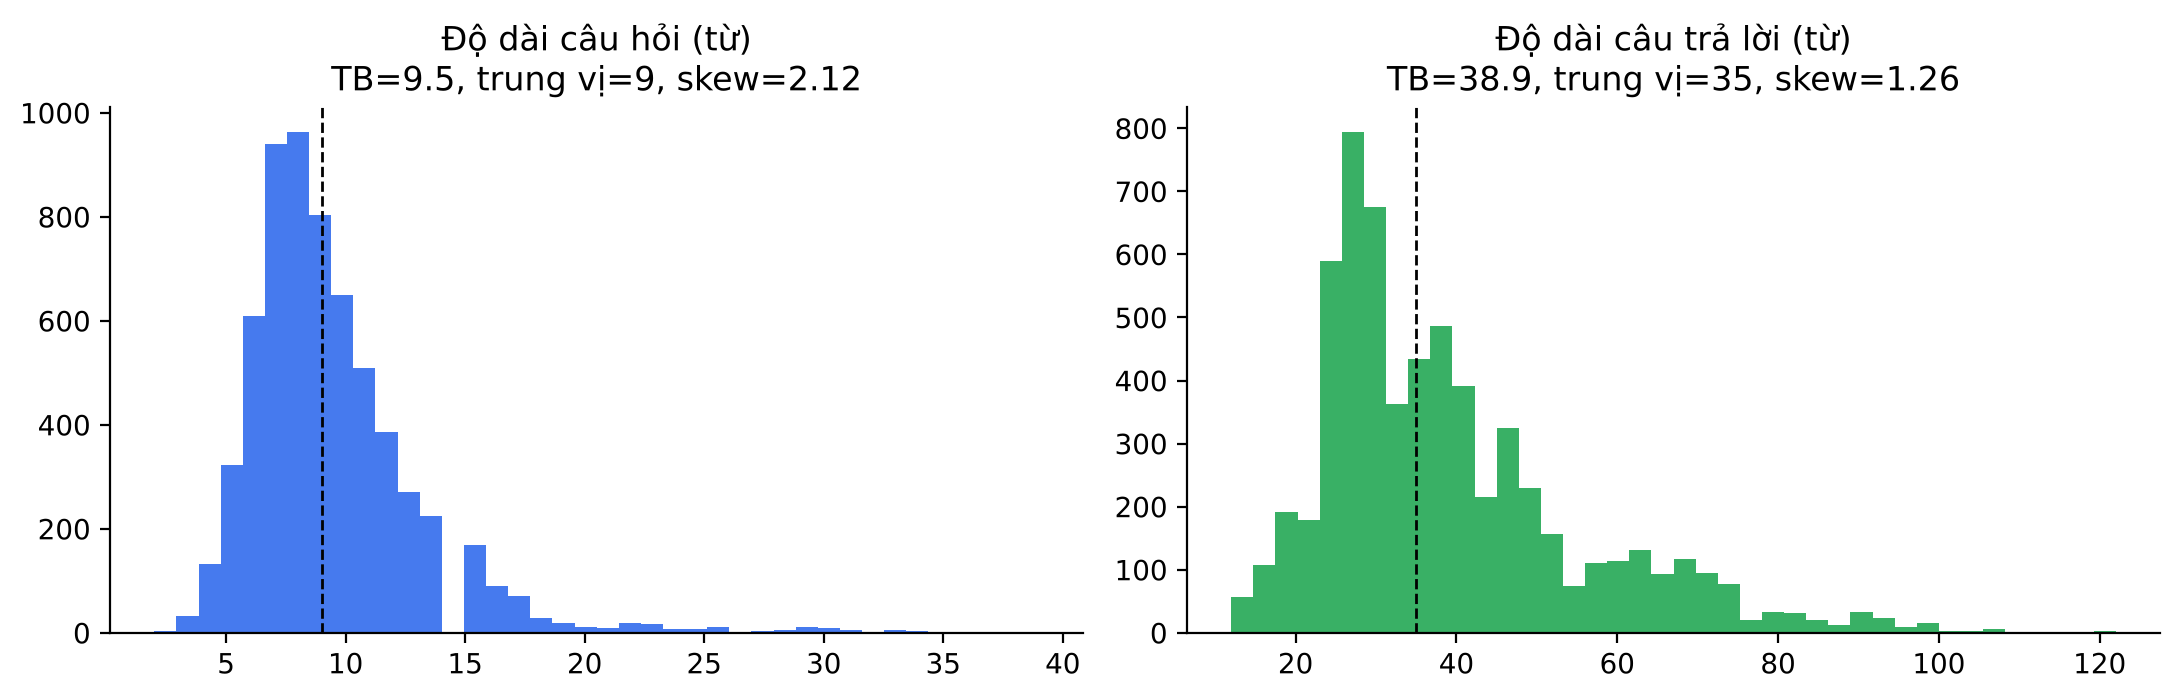

Câu hỏi TB 9.5 từ (p95 16), câu trả lời TB 38.9 từ (max 122); lệch phải (skew 2.12 / 1.26). Mẫu đơn lượt ngắn → `max_length` 1.024 token là đủ kể cả khi thêm ngữ cảnh RAG.

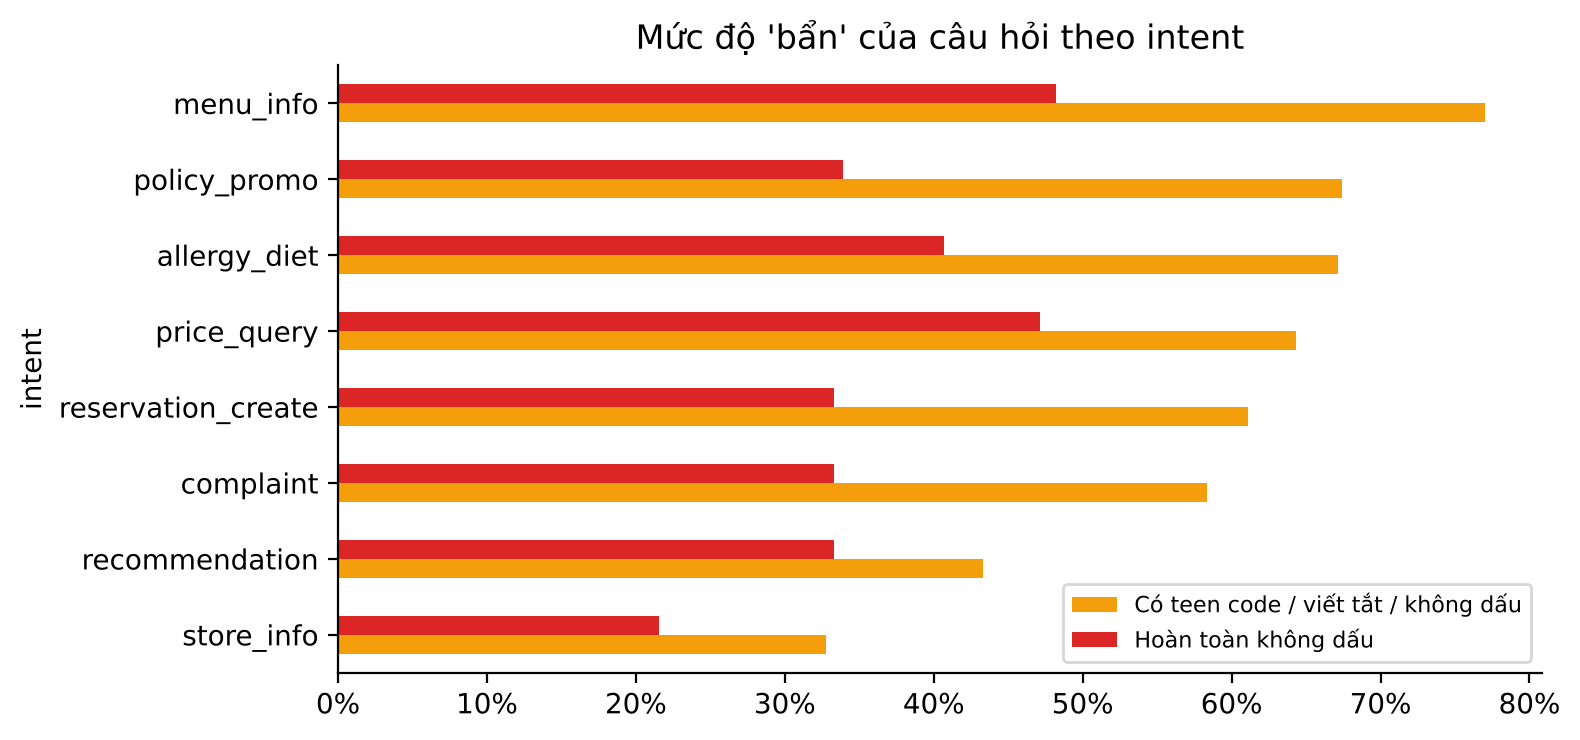

**69% câu hỏi có nhiễu, 44% hoàn toàn không dấu** → truy xuất phải chạy trên văn bản bỏ dấu; đánh giá riêng nhóm câu nhiễu (công bằng thuật toán).

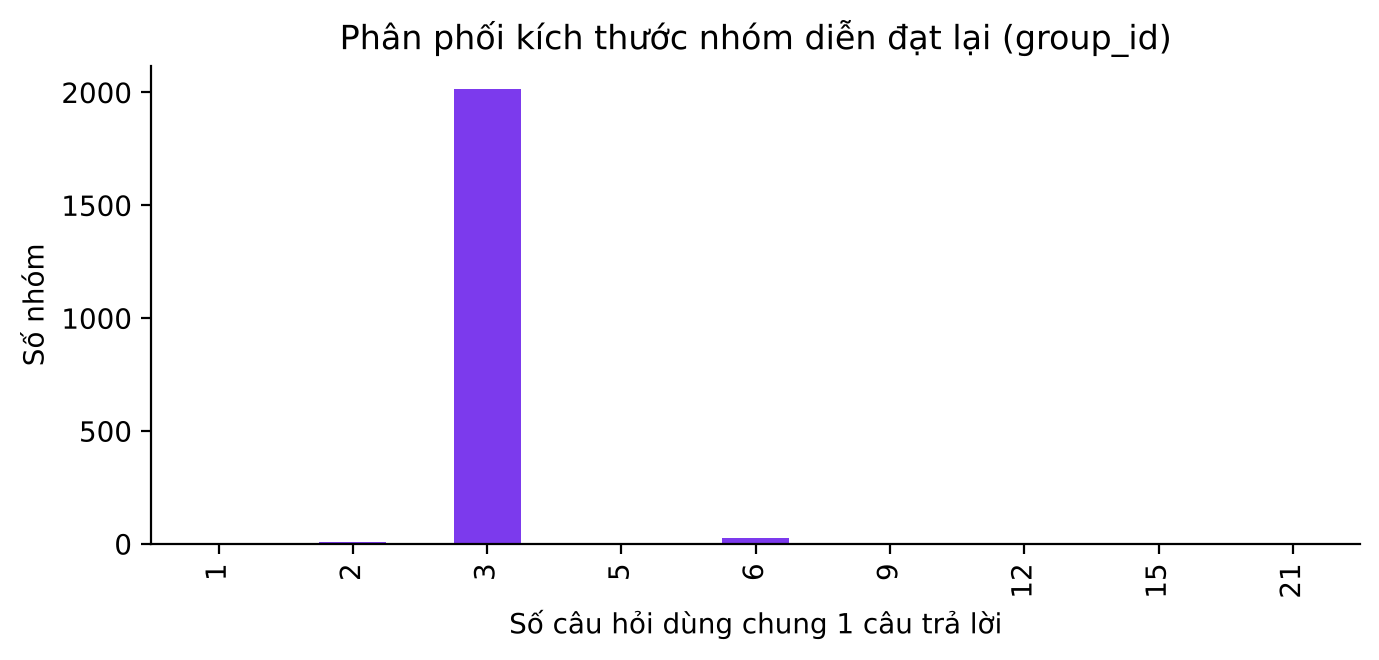

2,067 nhóm; 99.3% đáp án dùng chung ≥ 3 câu hỏi → bắt buộc chia theo nhóm.

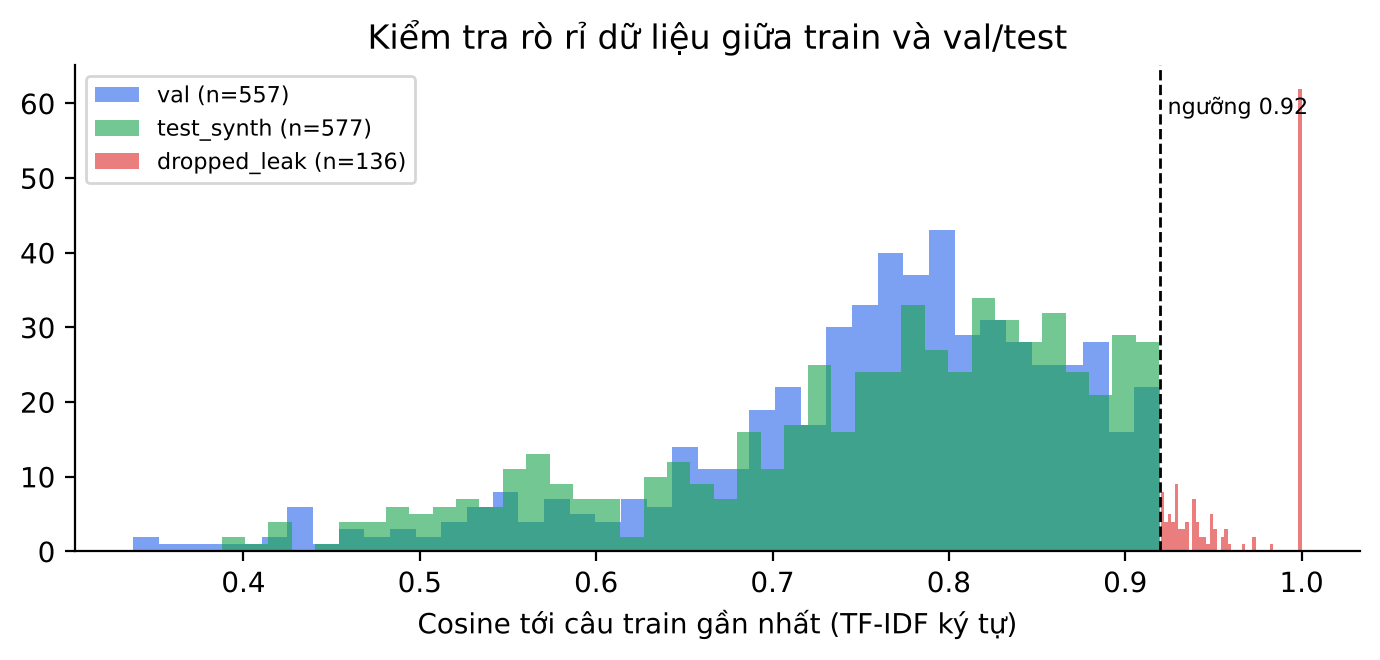

Sau khi loại, cosine val/test → train TB 0.755, max 0.920 (< 0,92).

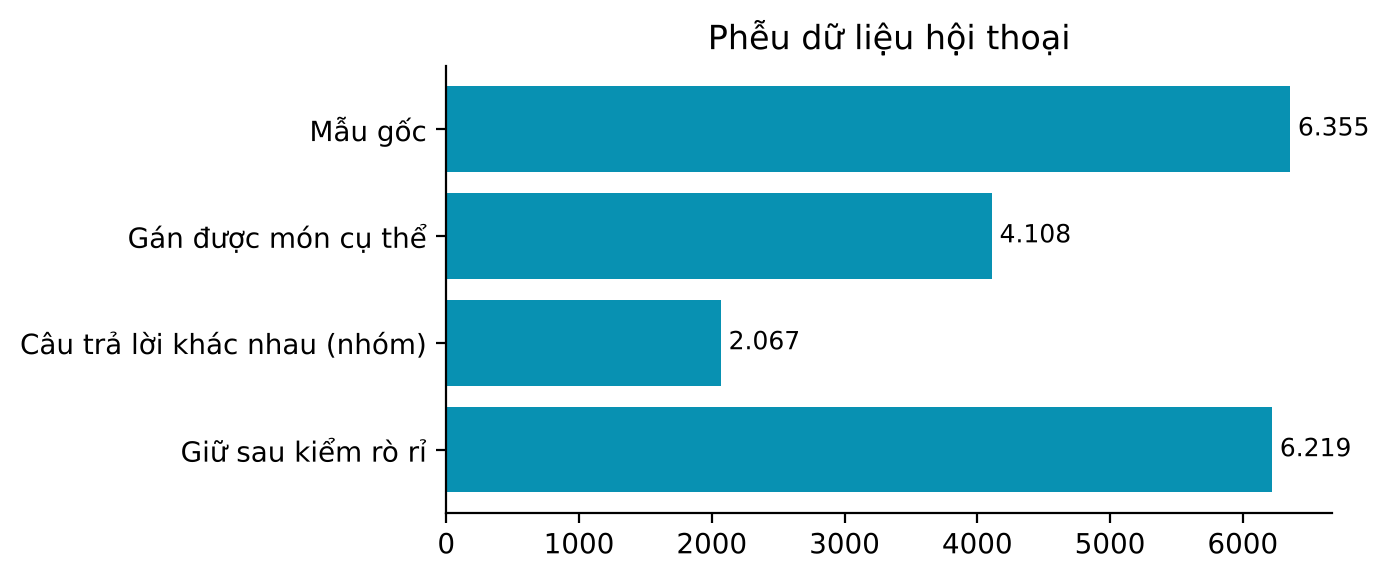

Phễu dữ liệu: mẫu gốc → gán được món → nhóm đáp án → giữ sau kiểm rò rỉ.

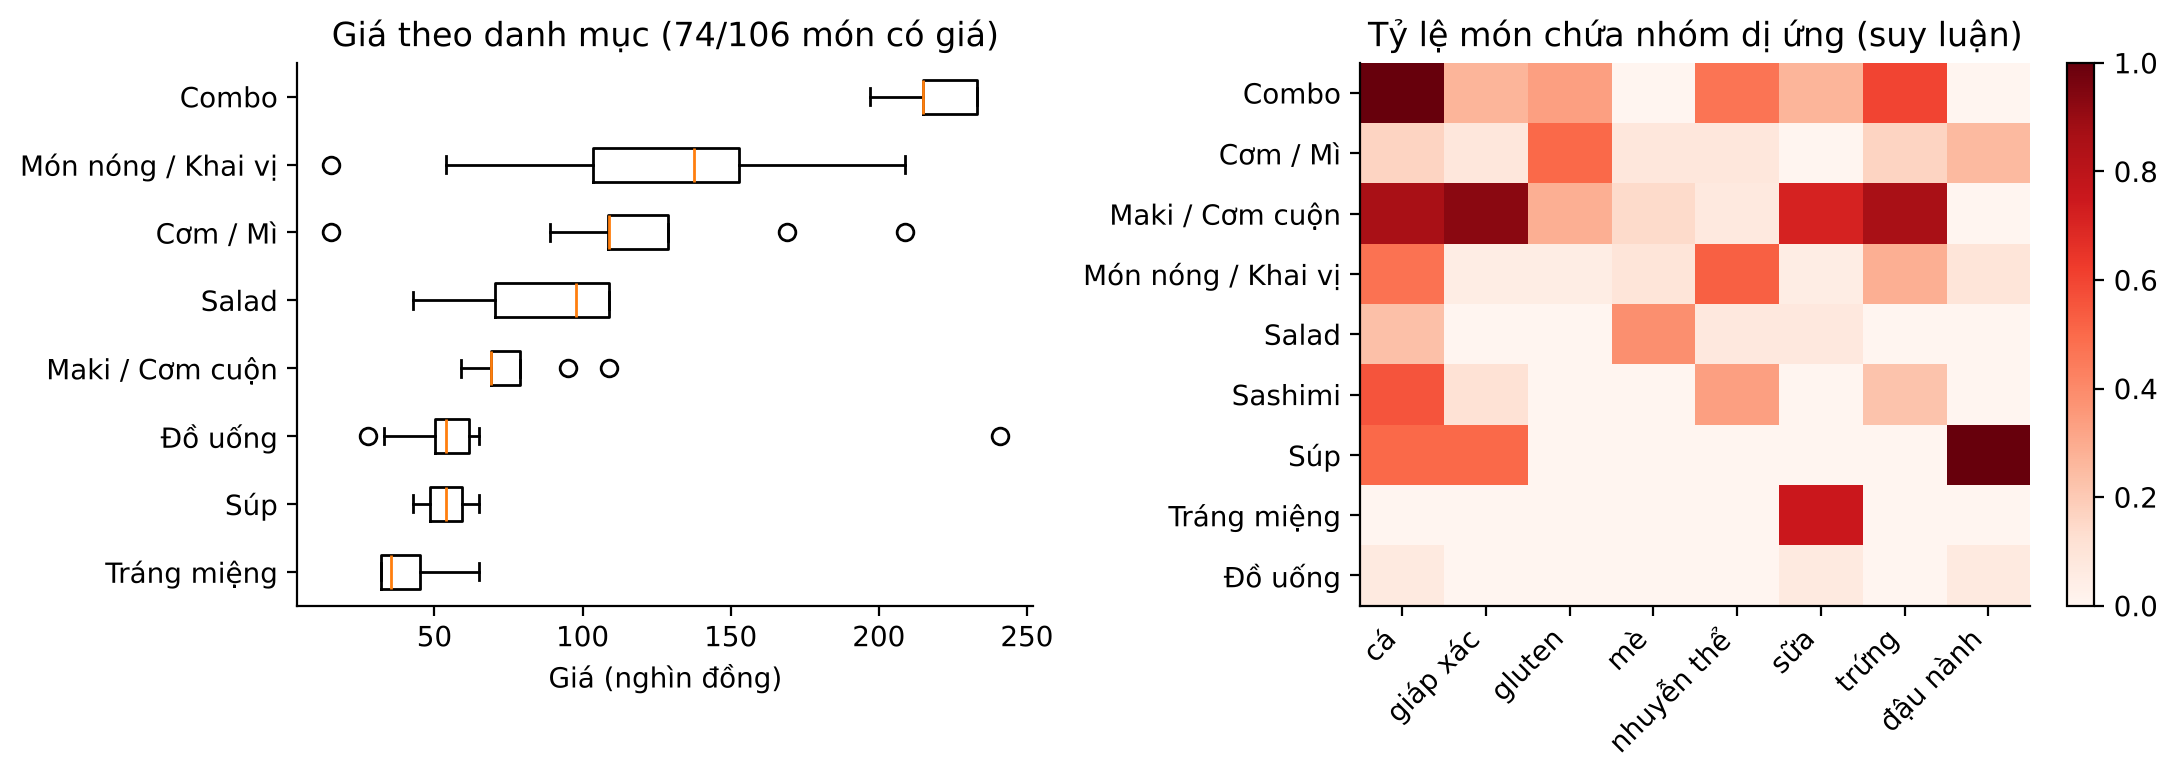

Giá trung vị 84,000 đ; 32/106 món thiếu giá ({'Combo': 10, 'Sashimi': 9, 'Món nóng / Khai vị': 6, 'Salad': 5, 'Maki / Cơm cuộn': 2}). Dị ứng phổ biến: cá 46%, trứng 29%, nhuyễn thể 23% — rủi ro tập trung ở Maki và Combo.

In [8]:
from kimochi import eda
E = eda.run_all()
def show(name, note):
    display(Image(f'images/{name}.png', width=820)); display(Markdown(note))
s = E['intent']['share']
show('eda_intent_split', f"**Intent lệch mạnh:** menu_info {s['menu_info']:.0%}, recommendation {s['recommendation']:.0%}, "
     f"allergy {s['allergy_diet']:.1%}, price {s['price_query']:.0%}; đặt bàn chỉ {s['reservation_create']:.1%}. Dữ liệu cũ thiên về "
     f"giới thiệu thực đơn, thiếu tác vụ giao dịch → bổ sung ở §7. Tỷ trọng intent giữa các tập lệch tối đa "
     f"{E['intent']['max_abs_share_gap_train_test']*100:.1f} điểm % (phân tầng tốt).")
L = E['lengths']
show('eda_lengths', f"Câu hỏi TB {L['q_mean']:.1f} từ (p95 {L['q_p95']:.0f}), câu trả lời TB {L['a_mean']:.1f} từ (max {L['a_max']}); "
     f"lệch phải (skew {L['q_skew']:.2f} / {L['a_skew']:.2f}). Mẫu đơn lượt ngắn → `max_length` 1.024 token là đủ kể cả khi thêm ngữ cảnh RAG.")
show('eda_noise', f"**{E['noise']['noisy_rate']:.0%} câu hỏi có nhiễu, {E['noise']['unaccented_rate']:.0%} hoàn toàn không dấu** → truy xuất "
     "phải chạy trên văn bản bỏ dấu; đánh giá riêng nhóm câu nhiễu (công bằng thuật toán).")
show('eda_group_size', f"{E['groups']['groups']:,} nhóm; {E['groups']['share_groups_ge3']:.1%} đáp án dùng chung ≥ 3 câu hỏi → bắt buộc chia theo nhóm.")
show('eda_leakage', f"Sau khi loại, cosine val/test → train TB {E['leakage']['kept_cos_mean']:.3f}, max {E['leakage']['kept_cos_max']:.3f} (< 0,92).")
show('eda_funnel', "Phễu dữ liệu: mẫu gốc → gán được món → nhóm đáp án → giữ sau kiểm rò rỉ.")
M = E['menu']
show('eda_menu', f"Giá trung vị {M['price_median']:,.0f} đ; {M['items'] - M['priced']}/{M['items']} món thiếu giá "
     f"({M['missing_price_by_cat']}). Dị ứng phổ biến: cá {M['allergen_share']['cá']:.0%}, trứng {M['allergen_share']['trứng']:.0%}, "
     f"nhuyễn thể {M['allergen_share']['nhuyễn thể']:.0%} — rủi ro tập trung ở Maki và Combo.")

## 7. Chuẩn hóa → bộ dữ liệu huấn luyện v2
Nguyên tắc: **fine-tuning dạy hành vi, cơ sở dữ liệu cung cấp sự thật.**
1. Làm sạch: bỏ cặp trùng, bỏ câu hỏi có đáp án mâu thuẫn.
2. Câu hỏi giá → **gọi công cụ** `get_menu_item` (kết quả lấy từ SQLite thật); món chưa có giá → từ chối có căn cứ; xóa giá trong
   câu trả lời không hỏi giá; loại dòng giá mâu thuẫn ngoài quy luật VAT.
3. **RAFT**: câu hỏi + 1 chunk đúng + 2 chunk nhiễu khó (BM25); 20% chỉ có chunk nhiễu → đáp án từ chối.
4. Mẫu theo khuôn (chạy công cụ thật trên bản sao DB): đặt bàn nhiều lượt có **xác nhận trước khi ghi**, chi nhánh, tìm món,
   khiếu nại → chuyển nhân viên, ngoài phạm vi / prompt injection → từ chối, chào hỏi.
5. 3 biến thể system prompt. Định dạng chuẩn `messages` (system / user / assistant / tool) + `meta`.

In [9]:
from kimochi import prepare_sft_v2
v2 = prepare_sft_v2.main()
print('Kích thước:', v2['split_sizes'], '| hội thoại nhiều lượt:', v2['multi_turn'])
print('Nhật ký làm sạch:', v2['cleaning_log']); print('Nguồn:', v2['source'])
fm = pd.DataFrame(v2['format_by_split']).fillna(0).astype(int); fm['tổng'] = fm.sum(axis=1)
display(fm.sort_values('tổng', ascending=False))

Kích thước: {'train': 4980, 'val': 580} | hội thoại nhiều lượt: 433
Nhật ký làm sạch: {'drop_exact_duplicate': 60, 'drop_conflicting_question': 239, 'price_stripped': 839, 'drop_price_inconsistent': 7, 'drop_price_unstrippable': 33}
Nguồn: {'kimochi_v1': 3991, 'kimochi_v1+raft': 1077, 'template_v2': 257, 'kimochi_v1+db': 235}


,train,val,tổng
closed_book,3587,404,3991
raft_pos,748,88,836
raft_neg,213,28,241
tool_price,207,23,230
reservation_mt,127,19,146
chitchat,16,1,17
handoff,13,1,14
tool_search,11,3,14
reservation_unavailable,12,2,14
oos_injection,9,3,12


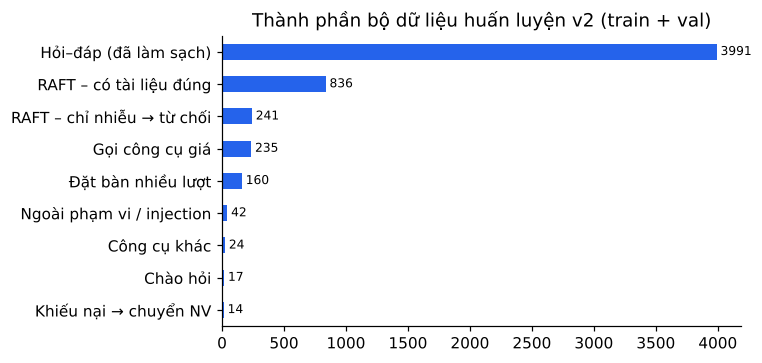

In [10]:
import matplotlib.pyplot as plt
group = {'closed_book': 'Hỏi–đáp (đã làm sạch)', 'raft_pos': 'RAFT – có tài liệu đúng', 'raft_neg': 'RAFT – chỉ nhiễu → từ chối',
         'tool_price': 'Gọi công cụ giá', 'tool_no_price': 'Gọi công cụ giá', 'reservation_mt': 'Đặt bàn nhiều lượt',
         'reservation_unavailable': 'Đặt bàn nhiều lượt', 'tool_branch': 'Công cụ khác', 'tool_search': 'Công cụ khác',
         'handoff': 'Khiếu nại → chuyển NV', 'chitchat': 'Chào hỏi'}
agg = fm['tổng'].groupby(lambda k: group.get(k, 'Ngoài phạm vi / injection')).sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4)); agg.plot.barh(ax=ax, color='#2563eb')
for i, v in enumerate(agg): ax.text(v, i, f' {v}', va='center', fontsize=8)
ax.set_title('Thành phần bộ dữ liệu huấn luyện v2 (train + val)'); fig.tight_layout(); fig.savefig('images/v2_composition.png', dpi=200)

In [11]:
v2_train = pd.read_json('data/splits_v2/train.jsonl', lines=True)
for fmt in ['tool_price', 'raft_neg', 'reservation_mt']:
    r = v2_train[v2_train.meta.map(lambda m: m['format']) == fmt].iloc[0]
    print('=' * 20, fmt)
    for m in r.messages[1:]:
        print(f"  [{m['role']:9}] {m['content'][:180]}")

==================== tool_price
  [user     ] Salad Gà Đào giá bao nhiêu?
  [assistant] <tool_call>{"name": "get_menu_item", "arguments": {"item": "Salad Gà Đào"}}</tool_call>
  [tool     ] {"found": true, "item": "Salad Gà Đào", "category": "Salad", "price_vnd": 109000, "allergens": [], "allergen_verified": false, "available": true}
  [assistant] Dạ một phần Salad Gà Đào có giá 109.000 VNĐ nha bạn, khẩu phần vừa đủ cho 1 người ăn đó ạ. 💸
==================== raft_neg
  [user     ] Ngữ cảnh:
[doc_menu_M067#c0] Rong Nho Sốt Mè (Size bé): Dạ Rong Nho Sốt Mè (Size bé) là món khai vị siêu hấp dẫn của tiệm nhà Chi đóiu. Rong nho tươi có vị hơi mặn nhẹ, khi dùng kè
  [assistant] Dạ câu này em chưa đủ thông tin để trả lời chắc chắn về Salad Rong Biển ạ. Khách iu gọi hotline 0879096969 (Bình Thạnh) / 0888912344 (Gò Vấp) hoặc để em chuyển nhân viên nha.
==================== reservation_mt
  [user     ] mình muốn đặt bàn 2 người ở Bình Thạnh
  [assistant] Dạ khách iu dự định đến lúc mấy giờ, ngà

## 8. Kiểm tra sẵn sàng huấn luyện & đánh giá
- **Huấn luyện:** mỗi lượt assistant → 1 mẫu *prompt / completion* (loss chỉ trên completion). Kiểm tra số mẫu và cấu trúc.
- **Đánh giá:** tập test v1 (giữ nguyên để so sánh công bằng) + bộ viết tay nếu đã khóa; bộ truy xuất chạy được.

In [12]:
from kimochi import llm, prompts, retriever
ds2, ds1 = llm.sft_dataset(ROOT, 'train'), llm.sft_dataset(ROOT, 'train', data_dir='splits')
dv2 = llm.sft_dataset(ROOT, 'val')
print(f'Mẫu huấn luyện v2: {len(ds2):,} (val {len(dv2):,}) | v1: {len(ds1):,}')
x = next(r for r in ds2 if len(r['prompt']) > 3)
print('Ví dụ prompt nhiều lượt — vai trò:', [m['role'] for m in x['prompt']], '→ completion:', x['completion'][0]['content'][:80])
assert all(r['completion'][0]['role'] == 'assistant' for r in ds2.select(range(500)))
tests = {n: len(prompts.load_eval_set(n)) for n in ['test_synth', 'test_gold', 'test_adv'] if (ROOT / f'data/splits/{n}.jsonl').exists()}
print('Tập đánh giá:', tests, '' if 'test_gold' in tests else '← CHƯA có test_gold viết tay (T06)')
R = retriever.HybridRetriever(retriever.load_docs())
for q in ['com cuon kieu cali bao nhieu tien', 'chi nhanh go vap mo cua may gio']:
    print(q, '→', [c['chunk_id'] for c in R.search_chunks(q, 'bm25_filter', k=3)])
try:   # độ dài token theo tokenizer thật (cần Internet tới Hugging Face)
    from transformers import AutoTokenizer
    tok = AutoTokenizer.from_pretrained('Qwen/Qwen2.5-3B-Instruct')
    n = [len(tok.apply_chat_template(r['prompt'] + r['completion'], tokenize=True)) for r in ds2.select(range(2000))]
    print('Token / mẫu (Qwen):', pd.Series(n).describe(percentiles=[.5, .95, .99]).round(0).to_dict())
except Exception as e:
    print('Bỏ qua đếm token (không truy cập được Hugging Face):', type(e).__name__)

Mẫu huấn luyện v2: 5,843 (val 704) | v1: 5,085
Ví dụ prompt nhiều lượt — vai trò: ['system', 'user', 'assistant', 'tool'] → completion: Dạ một phần Salad Gà Đào có giá 109.000 VNĐ nha bạn, khẩu phần vừa đủ cho 1 ngườ
Tập đánh giá: {'test_synth': 577} ← CHƯA có test_gold viết tay (T06)


com cuon kieu cali bao nhieu tien → ['doc_menu_M033#c3', 'doc_menu_M033#c0', 'doc_menu_M033#c1']
chi nhanh go vap mo cua may gio → ['doc_policy_031#c0', 'doc_policy_276#c0', 'doc_policy_263#c0']


[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Bỏ qua đếm token (không truy cập được Hugging Face): OSError


## 9. Manifest dữ liệu
Ghi md5 các file dữ liệu → NB2 kiểm tra trước khi huấn luyện.

In [13]:
from kimochi import manifest
mf = manifest.write()
display(pd.DataFrame(mf).T)
assert manifest.verify() == []
print('✓ Dữ liệu sẵn sàng cho NB2')

,md5,rows
data/kimochi.db,cacb499c4b62ffa47349bfb873970e1e,None
data/kb/menu.csv,c95a4881a3c3f165d079efab8f92f932,None
data/kb/chunks.jsonl,4ec4c4be93ca369f34ae5739eacb5119,1019
data/splits/train.jsonl,630b24cb873218cfd4b4a8817e43e1c4,5085
data/splits/val.jsonl,6e9103a3e8f4ea0ee825706582f875c8,557
data/splits/test_synth.jsonl,e61ceed6653f7a70103c081751b448cc,577
data/splits_v2/train.jsonl,2e6f3520a102044dd5d357546f13557f,4980
data/splits_v2/val.jsonl,0260fcfbe61bc07e7dd079931c743818,580


✓ Dữ liệu sẵn sàng cho NB2
